In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv('/content/heart.csv')
print("Dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("\nMissing values in raw data:\n", df.isnull().sum())
df.head()

Dataset shape: (918, 12)
Duplicate rows: 0

Missing values in raw data:
 Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [8]:
# In clinical readings, Cholesterol and RestingBP cannot be 0
print("Zero entries in Cholesterol:", (df['Cholesterol'] == 0).sum())
print("Zero entries in RestingBP:", (df['RestingBP'] == 0).sum())

# Replace 0s with NaN so we can impute them properly inside the pipeline
df['Cholesterol'] = df['Cholesterol'].replace(0, np.nan)
df['RestingBP'] = df['RestingBP'].replace(0, np.nan)

print("\nMissing values after converting 0s:\n", df.isnull().sum())
df.describe()

Zero entries in Cholesterol: 172
Zero entries in RestingBP: 1

Missing values after converting 0s:
 Age                 0
Sex                 0
ChestPainType       0
RestingBP           1
Cholesterol       172
FastingBS           0
RestingECG          0
MaxHR               0
ExerciseAngina      0
Oldpeak             0
ST_Slope            0
HeartDisease        0
dtype: int64


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,917.000000,746.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.540894,244.635389,0.233115,136.809368,0.887364,0.553377
std,9.432617,17.999749,59.153524,0.423046,25.460334,1.066570,0.497414
min,28.000000,80.000000,85.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,207.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,237.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,275.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


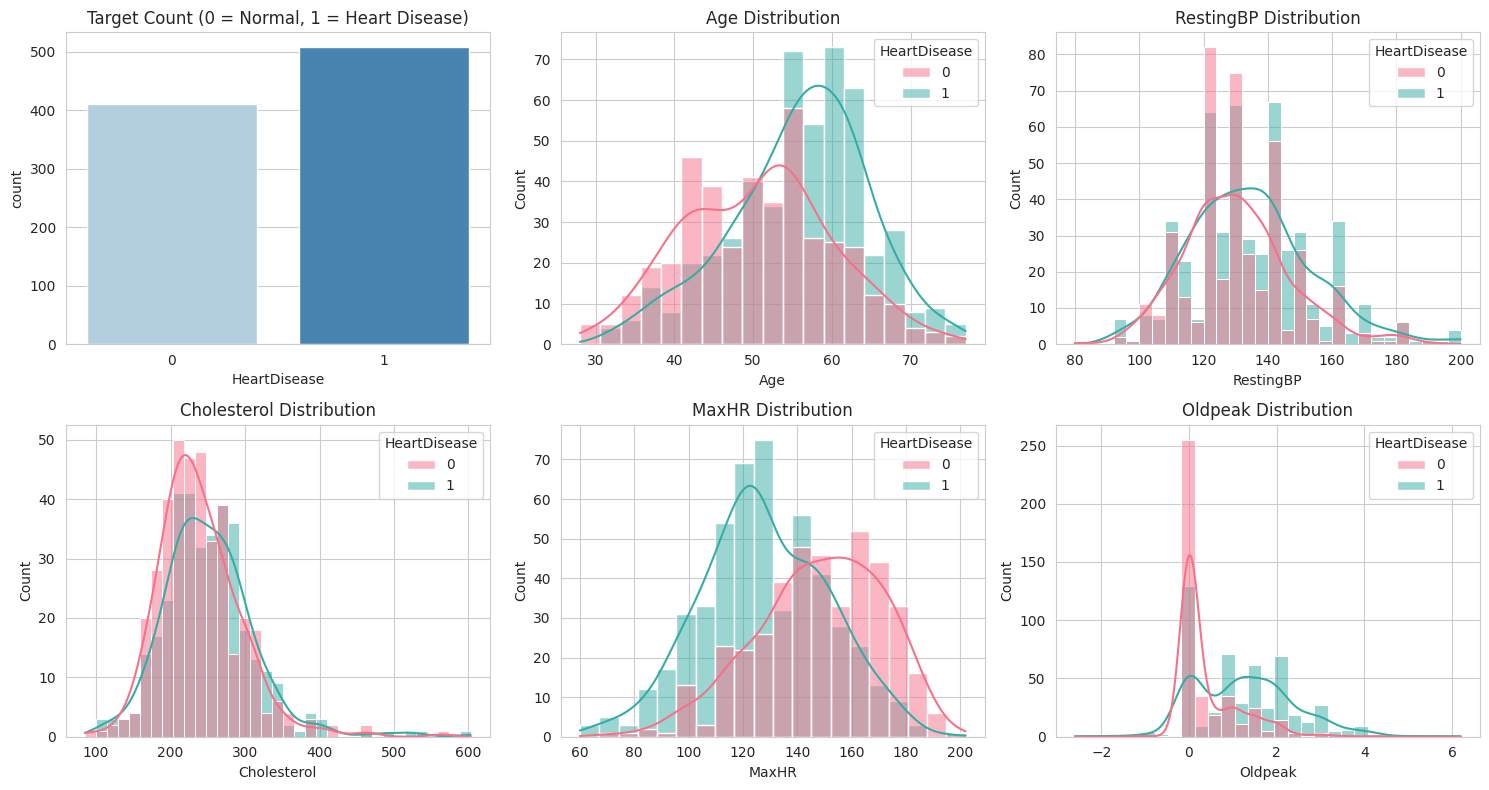

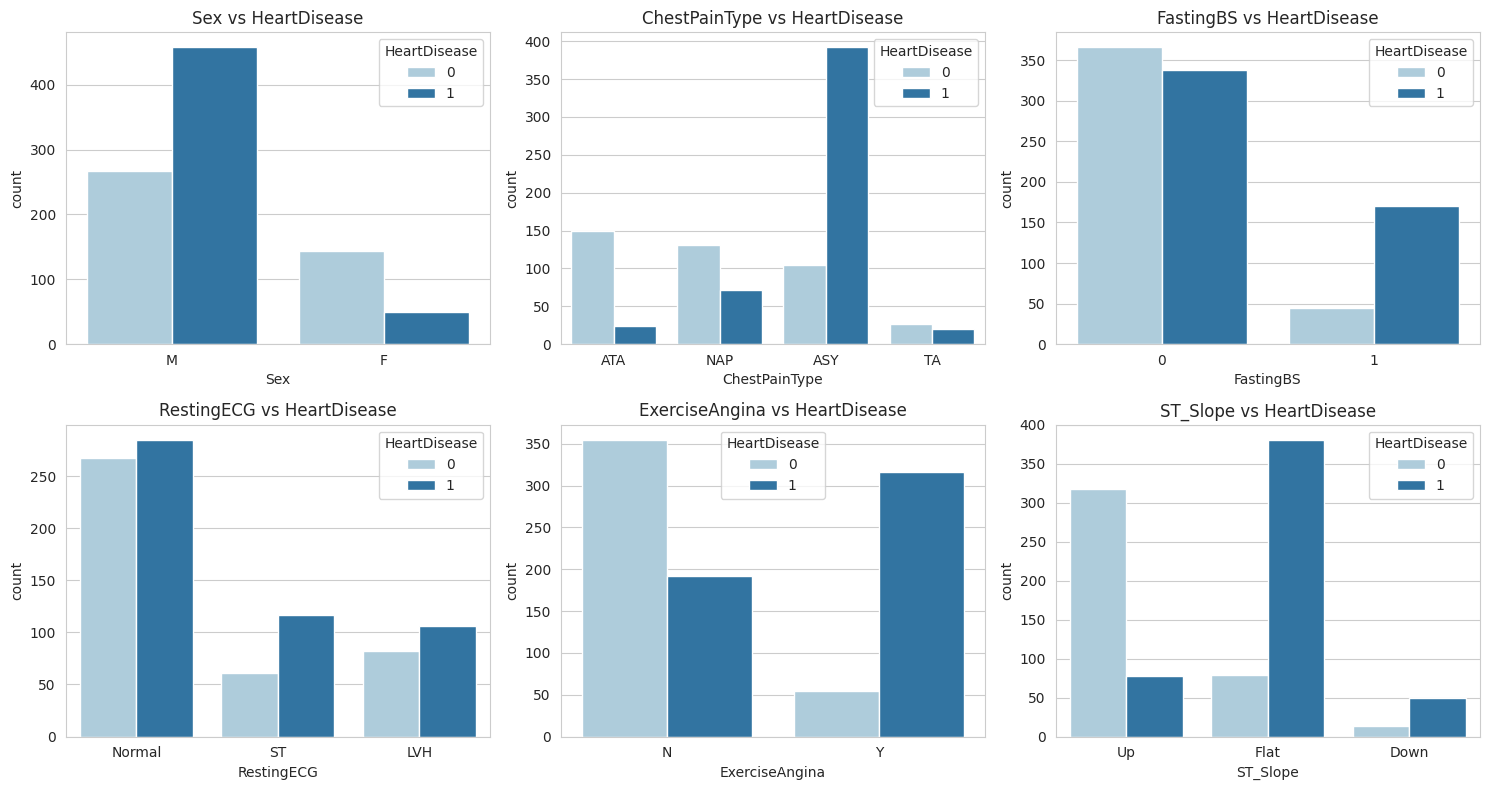

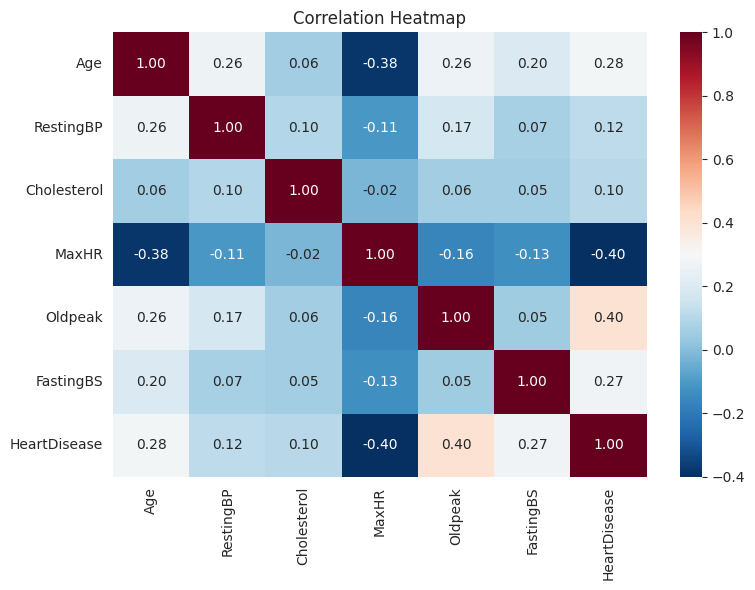

In [9]:
sns.set_style("whitegrid")
num_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
cat_cols = ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

# 1. Numerical distributions
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
sns.countplot(data=df, x='HeartDisease', ax=axes[0, 0], palette='Blues')
axes[0, 0].set_title('Target Count (0 = Normal, 1 = Heart Disease)')

for i, col in enumerate(num_cols):
    r, c = (i + 1) // 3, (i + 1) % 3
    sns.histplot(data=df, x=col, hue='HeartDisease', kde=True, ax=axes[r, c], palette='husl')
    axes[r, c].set_title(f'{col} Distribution')

plt.tight_layout()
plt.savefig('eda_distributions.png', dpi=300)
plt.show()

# 2. Categorical features vs Target
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(cat_cols):
    r, c = i // 3, i % 3
    sns.countplot(data=df, x=col, hue='HeartDisease', ax=axes[r, c], palette='Paired')
    axes[r, c].set_title(f'{col} vs HeartDisease')

plt.tight_layout()
plt.savefig('categorical_analysis.png', dpi=300)
plt.show()

# 3. Correlation Heatmap
plt.figure(figsize=(8, 6))
corr = df[num_cols + ['FastingBS', 'HeartDisease']].corr()
sns.heatmap(corr, annot=True, cmap='RdBu_r', fmt='.2f')
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.savefig('correlation_matrix.png', dpi=300)
plt.show()

In [10]:
# Welch's t-test for MaxHR (normally distributed continuous variable)
hr_0 = df[df['HeartDisease'] == 0]['MaxHR']
hr_1 = df[df['HeartDisease'] == 1]['MaxHR']
t_stat, p_hr = stats.ttest_ind(hr_0, hr_1, equal_var=False)
print(f"T-test (MaxHR): t = {t_stat:.4f}, p-value = {p_hr:.4e}")

# Mann-Whitney U test for Oldpeak (skewed continuous variable)
op_0 = df[df['HeartDisease'] == 0]['Oldpeak']
op_1 = df[df['HeartDisease'] == 1]['Oldpeak']
u_stat, p_op = stats.mannwhitneyu(op_0, op_1)
print(f"Mann-Whitney U test (Oldpeak): U = {u_stat:.4f}, p-value = {p_op:.4e}")

# Chi-Square test for ChestPainType (categorical variable)
ct = pd.crosstab(df['ChestPainType'], df['HeartDisease'])
chi2_stat, p_cp, _, _ = stats.chi2_contingency(ct)
print(f"Chi-Square test (ChestPainType): chi2 = {chi2_stat:.4f}, p-value = {p_cp:.4e}")

T-test (MaxHR): t = 13.2315, p-value = 1.4306e-36
Mann-Whitney U test (Oldpeak): U = 55164.0000, p-value = 6.7678e-37
Chi-Square test (ChestPainType): chi2 = 268.0672, p-value = 8.0837e-58


In [11]:
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, RocCurveDisplay

X = df.drop('HeartDisease', axis=1)
y = df['HeartDisease']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ohe', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols)
])

models_list = {
    'Baseline': (DummyClassifier(strategy='most_frequent'), {}),
    'Logistic Regression': (LogisticRegression(max_iter=1000, random_state=42), {'model__C': [0.1, 1.0, 10.0]}),
    'SVM': (SVC(probability=True, random_state=42), {'model__C': [0.5, 1.0, 2.0], 'model__kernel': ['rbf', 'linear']}),
    'Random Forest': (RandomForestClassifier(random_state=42), {'model__n_estimators': [100, 150], 'model__max_depth': [5, 8, None]}),
    'Gradient Boosting': (GradientBoostingClassifier(random_state=42), {'model__n_estimators': [100, 150], 'model__learning_rate': [0.05, 0.1]})
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
eval_rows = []
trained_models = {}

for name, (clf, params) in models_list.items():
    full_pipe = Pipeline([('prep', preprocessor), ('model', clf)])

    if params:
        search = GridSearchCV(full_pipe, params, cv=cv, scoring='roc_auc', n_jobs=-1)
        search.fit(X_train, y_train)
        best_model = search.best_estimator_
    else:
        best_model = full_pipe.fit(X_train, y_train)

    trained_models[name] = best_model
    preds = best_model.predict(X_test)
    probs = best_model.predict_proba(X_test)[:, 1]

    eval_rows.append({
        'Model': name,
        'Accuracy': round(accuracy_score(y_test, preds), 4),
        'Precision': round(precision_score(y_test, preds, zero_division=0), 4),
        'Recall': round(recall_score(y_test, preds, zero_division=0), 4),
        'F1-Score': round(f1_score(y_test, preds, zero_division=0), 4),
        'ROC-AUC': round(roc_auc_score(y_test, probs), 4)
    })

eval_df = pd.DataFrame(eval_rows).sort_values(by='ROC-AUC', ascending=False)
eval_df

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
4,Gradient Boosting,0.8859,0.8932,0.9020,0.8976,0.9350
1,Logistic Regression,0.8859,0.8857,0.9118,0.8986,0.9329
2,SVM,0.8533,0.8788,0.8529,0.8657,0.9319
3,Random Forest,0.8587,0.8800,0.8627,0.8713,0.9196
0,Baseline,0.5543,0.5543,1.0000,0.7133,0.5000


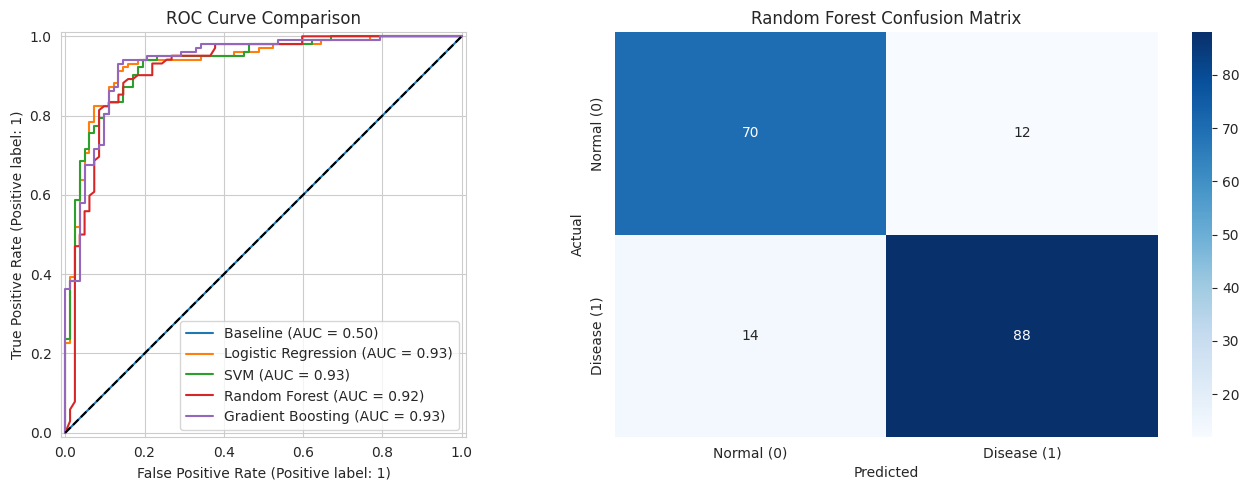

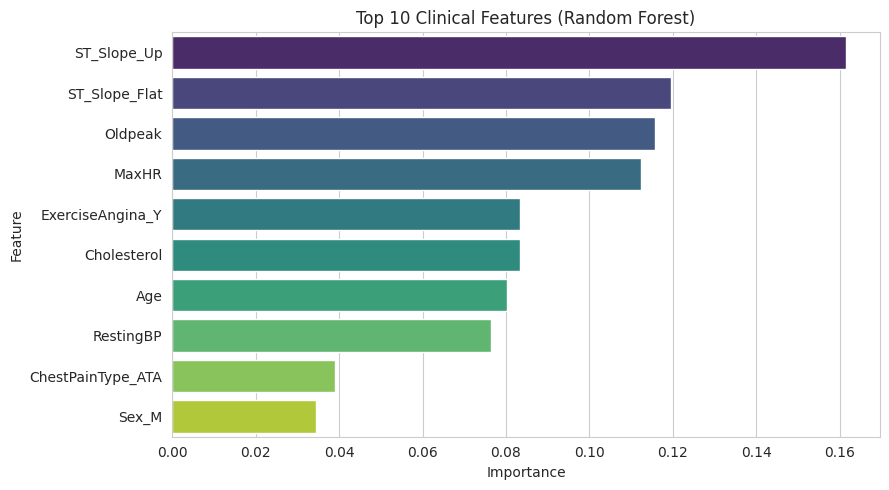

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

for name, m in trained_models.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, ax=ax[0], name=name)
ax[0].plot([0, 1], [0, 1], 'k--')
ax[0].set_title('ROC Curve Comparison')

rf_preds = trained_models['Random Forest'].predict(X_test)
cm = confusion_matrix(y_test, rf_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax[1],
            xticklabels=['Normal (0)', 'Disease (1)'],
            yticklabels=['Normal (0)', 'Disease (1)'])
ax[1].set_title('Random Forest Confusion Matrix')
ax[1].set_xlabel('Predicted')
ax[1].set_ylabel('Actual')

plt.tight_layout()
plt.savefig('model_evaluation.png', dpi=300)
plt.show()

rf_step = trained_models['Random Forest'].named_steps['model']
cat_names = trained_models['Random Forest'].named_steps['prep'].named_transformers_['cat'].named_steps['ohe'].get_feature_names_out(cat_cols)
all_features = num_cols + list(cat_names)

imp_df = pd.DataFrame({'Feature': all_features, 'Importance': rf_step.feature_importances_}).sort_values('Importance', ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(data=imp_df.head(10), x='Importance', y='Feature', palette='viridis')
plt.title('Top 10 Clinical Features (Random Forest)')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=300)
plt.show()